[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch20_08_SKOOL_LSTM_PROJECT.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 20: LSTM and GRU** (Part IV: Meaning and Memory). This is the kids' course edition of the lab, kept for comparison.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=20](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=20)
* The video course this book grew from: [www.aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# 🌍 LSTM Project: Predict Real-World Data!

Pick a dataset in the big cell below (`DATASET = ...`), then run both cells. The LSTM reads the last 10 values
and predicts the next one.

**How to judge it:** the notebook also runs the simplest forecast there is, *"the next value will be the same as
the last one"*. On slowly changing data (sunspots, temperatures) that rule is already good, so a model is only
interesting if it **beats** it. That comparison is the number to look at.

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Fair scaling.** The min–max scaling was fitted on the whole series, test months included, so the model had a peek at the test range. It now uses only the training part.
> * **A real test.** The test months were also used as validation data during training. Now the last 15% of the training period is the validation set, early stopping (patience 15) keeps the best epoch instead of always running 200, and the test months are used once.
> * **A yardstick.** Results are compared with the "same as last time" forecast, and the star rating measures how much the LSTM beats it. The percentage error was removed: sunspot counts are often near zero, where a small miss becomes an enormous percentage.
> * **LSTMs use their default tanh** (the three layers had `activation='relu'`, which makes the memory unbounded and training fragile).
> * The "TEMPERATURE" option downloads daily **minimum** temperatures in **Melbourne, Australia** (1981–1990), not Delhi; the story now says so, with summer in December–February. Fallback data is now labelled as made up. `except:` became `except Exception:` (1×). A title cell was added; emoji removed from 9 plot titles.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
keras.utils.set_random_seed(42)   # Python, NumPy and TensorFlow in one call: the same run every time

print("✅ Libraries loaded!")
print(f"TensorFlow: {tf.__version__}")
print(f"Keras: {keras.__version__}")

✅ Libraries loaded!
TensorFlow: 2.21.0
Keras: 3.14.1


🌍 REAL-WORLD LSTM PREDICTION CHALLENGE!

☀️ SUNSPOT DATASET

    📖 THE STORY:
    Sunspots are dark spots on the Sun! Scientists have counted them
    every month since 1749 (over 270 years ago! 🔭)

    Notice the PATTERN:
    • Sunspots go up and down in an 11-YEAR CYCLE!
    • Sometimes lots of spots, sometimes almost none
    • This affects radio signals and even Earth's weather!

    🎯 YOUR MISSION: Predict how many sunspots next month!
    
📥 Downloading sunspot data...
✅ Downloaded 500 months of sunspot data!

📊 Dataset: Monthly Sunspot Count
   Total data points: 500
   Range: 0.0 to 238.9 sunspots


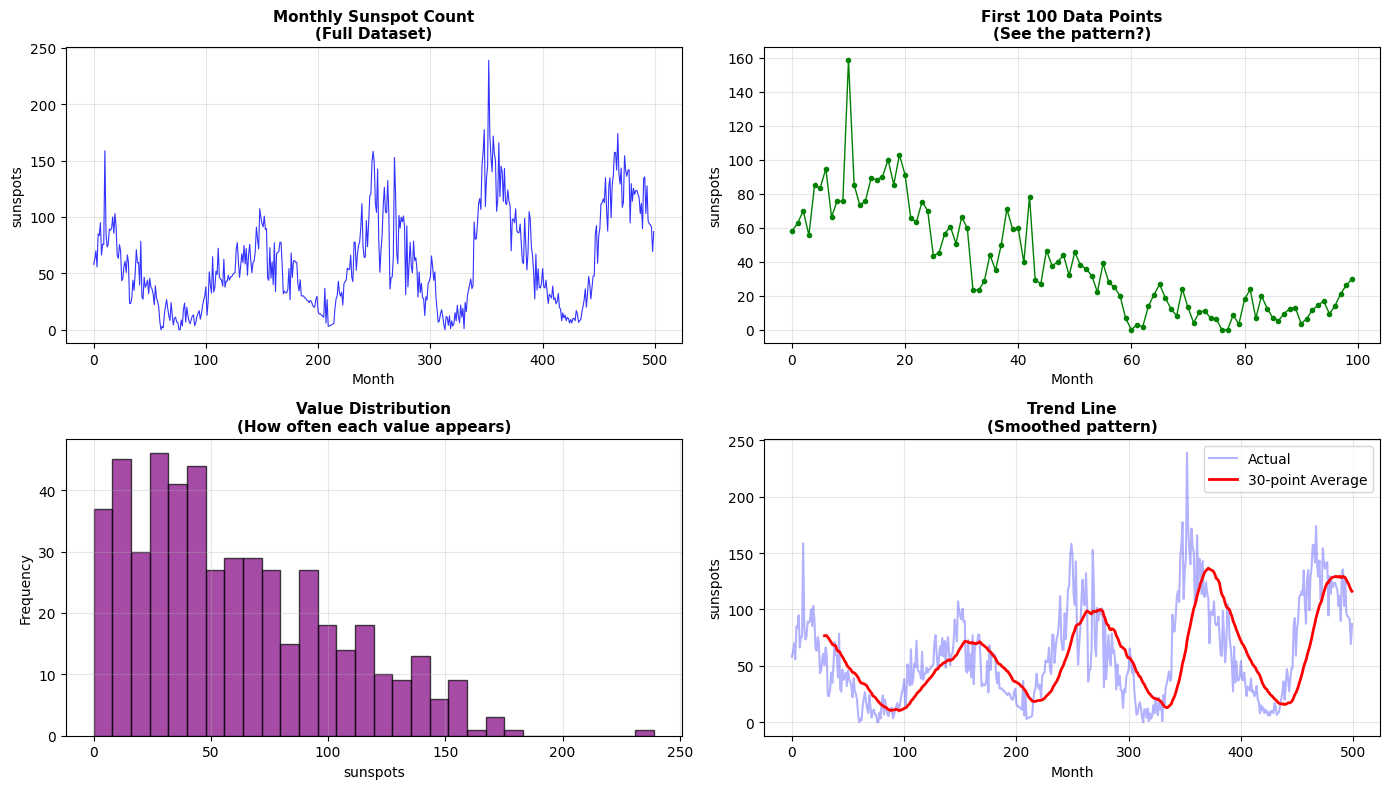


🧠 TRAINING LSTM ON REAL DATA

📦 Data prepared:
   Window size: 10 (uses last 10 values to predict next)
   Training samples: 392
   Testing samples: 98



⏳ Training LSTM on Monthly Sunspot Count...
   (This might take a minute - real data is harder!)

   (62,881 parameters learning from 334 windows: watch for memorising!)
Epoch 1/200


11/11 - 3s - 310ms/step - loss: 0.0274 - mae: 0.1268 - val_loss: 0.0213 - val_mae: 0.1148


Epoch 2/200


11/11 - 0s - 13ms/step - loss: 0.0128 - mae: 0.0900 - val_loss: 0.0479 - val_mae: 0.1698


Epoch 3/200


... (67 outputs left out)

Epoch 37/200


11/11 - 0s - 13ms/step - loss: 0.0064 - mae: 0.0585 - val_loss: 0.0226 - val_mae: 0.1100


   Stopped after 37 epochs (best weights kept).

✅ Training complete!

📊 HOW WELL DID THE LSTM LEARN?



📈 Results:
   LSTM average error:                     16.38 sunspots
   'Same as last time' rule average error: 12.09 sunspots
   👉 The simple rule wins by 36%! The LSTM has not learned more than 'same as last time'.


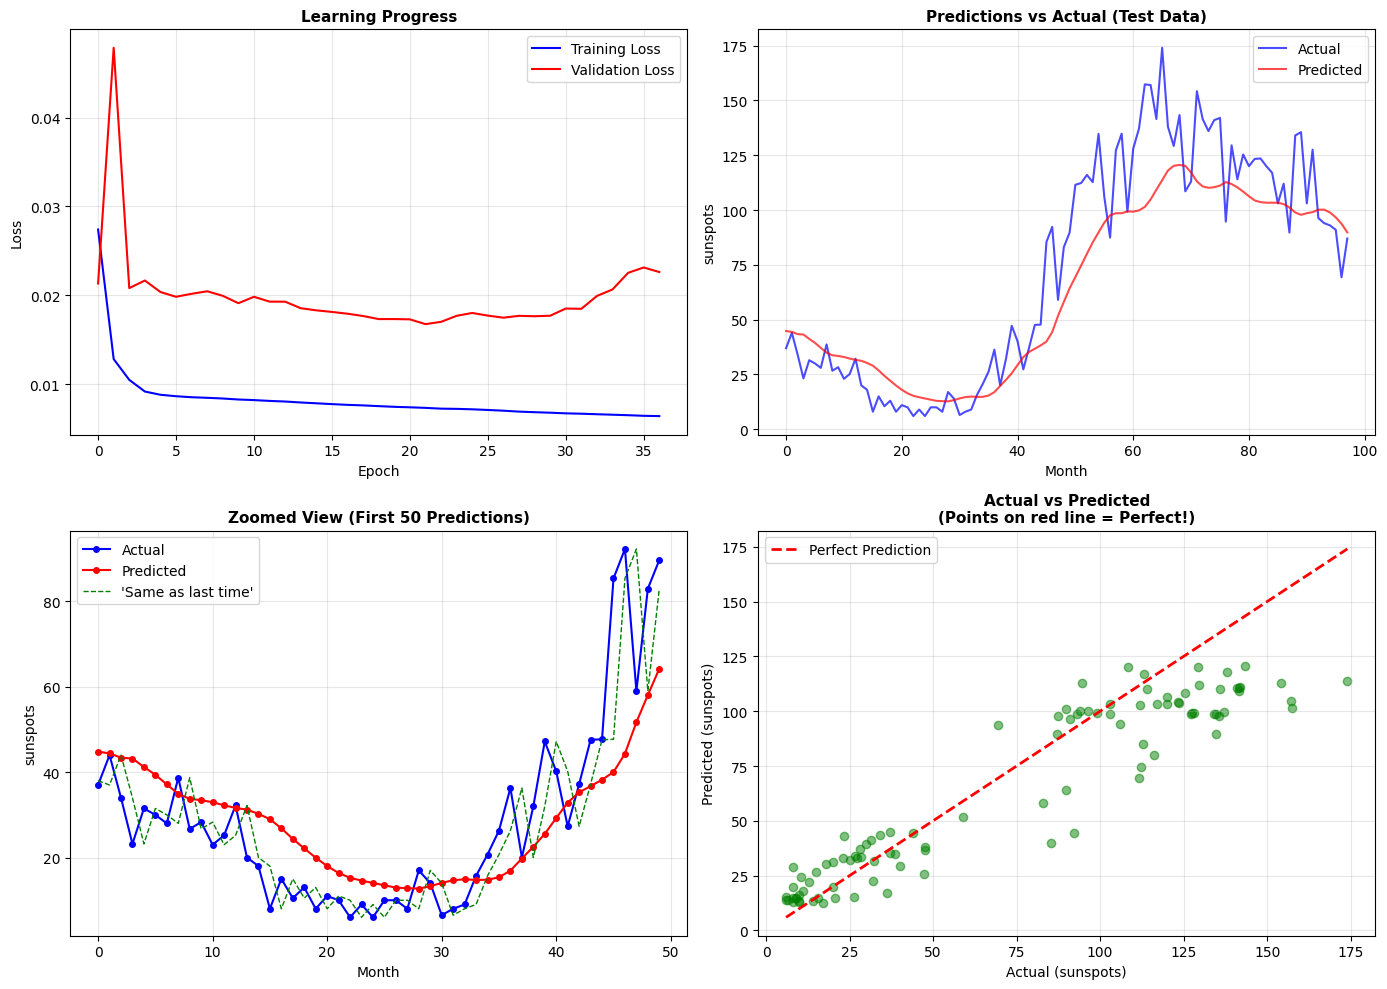


🔮 PREDICT THE FUTURE!

📝 Last 10 known values:
   ['134.0', '135.5', '103.0', '127.5', '96.3', '94.0', '93.0', '91.0', '69.3', '87.0']

🔮 LSTM's prediction for NEXT value: 85.8 sunspots

📈 Generating next 10 predictions...


   Future predictions: ['85.8', '82.9', '80.9', '79.4', '78.6', '77.8', '77.2', '76.6', '76.1', '75.3']


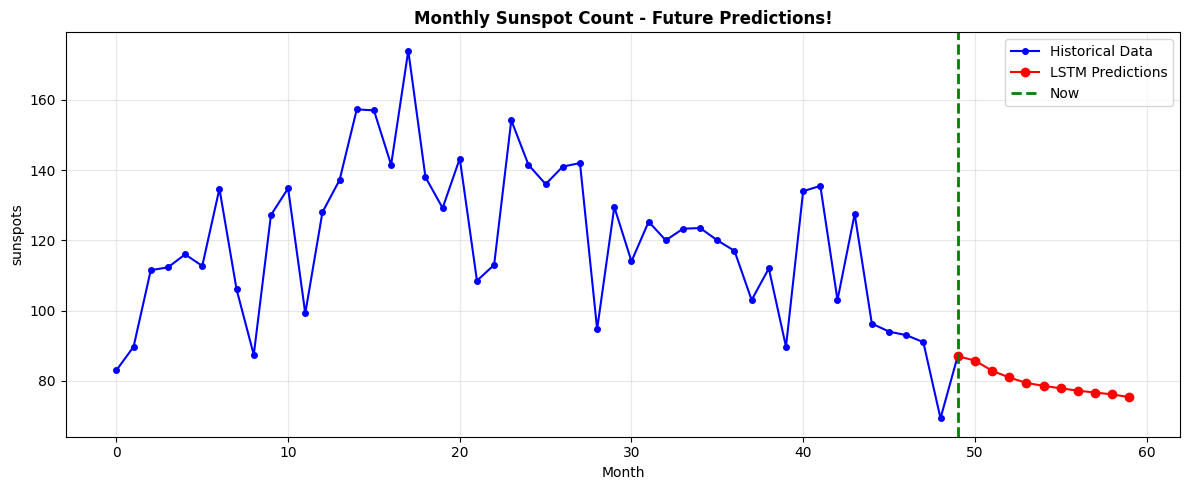


📋 SUMMARY

   Dataset: Monthly Sunspot Count
   Data points used: 500

   Performance:
   • LSTM average error: 16.38 sunspots
   • 'Same as last time' error: 12.09 sunspots
   • Rating (how much it beats the simple rule): 🌟

   💡 What the LSTM learned:

   • Sunspots follow an ~11 year CYCLE
   • Very hard to predict exactly (chaotic!)

   🎮 TRY THIS:
   • Change DATASET to try other real-world problems!
   • Did the simple rule win? Make the LSTM predict the CHANGE from the last value
     (y = next - last) instead of the value itself. Then it starts from 'same as last time'
     and only has to learn the correction.
   • Fewer parameters: try LSTM(16) alone. Is it worse, or better, than the big stack?
   • Options: "PASSENGERS", "TEMPERATURE", "SUNSPOTS", "BIKES", "ELECTRICITY"



In [2]:
# ============================================================================
# 🌍 REAL-WORLD LSTM CHALLENGE!
# ============================================================================

# ╔════════════════════════════════════════════════════════════════════════════╗
# ║  🎯 PREDICT REAL DATA!                                                     ║
# ║                                                                            ║
# ║  Choose a real-world problem:                                              ║
# ║                                                                            ║
# ║  "PASSENGERS" = ✈️ How many people will fly on airplanes next month?       ║
# ║  "TEMPERATURE"= 🌡️ What will the temperature be tomorrow?                  ║
# ║  "SUNSPOTS"   = ☀️ How many sunspots will appear on the sun?               ║
# ║  "BIKES"      = 🚲 How many bikes will people rent tomorrow?               ║
# ║  "ELECTRICITY"= 💡 How much electricity will a house use?                  ║
# ╚════════════════════════════════════════════════════════════════════════════╝

# ===== 👇 CHOOSE YOUR DATASET! 👇 =====
DATASET = "SUNSPOTS"  # Options: "PASSENGERS", "TEMPERATURE", "SUNSPOTS", "BIKES", "ELECTRICITY"
# ======================================

import urllib.request
import io

print("=" * 65)
print("🌍 REAL-WORLD LSTM PREDICTION CHALLENGE!")
print("=" * 65)

# ============================================================================
# 📥 DOWNLOAD AND PREPARE REAL DATA
# ============================================================================

if DATASET.upper() == "PASSENGERS":
    # ✈️ AIRLINE PASSENGERS (1949-1960)
    # Monthly totals of international airline passengers
    # Source: Box & Jenkins (1976) - Famous dataset!

    print("\n✈️ AIRLINE PASSENGERS DATASET")
    print("=" * 65)
    print("""
    📖 THE STORY:
    This data shows how many thousands of people flew on airplanes
    each month from 1949 to 1960.

    Notice the PATTERN:
    • More people fly in SUMMER (vacations! ☀️)
    • Fewer people fly in WINTER (cold! ❄️)
    • Overall, MORE people fly each year (planes got popular! 📈)

    🎯 YOUR MISSION: Predict how many passengers next month!
    """)

    # Classic airline passengers data
    data = np.array([
        112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,  # 1949
        115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,  # 1950
        145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,  # 1951
        171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,  # 1952
        196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,  # 1953
        204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,  # 1954
        242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,  # 1955
        284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,  # 1956
        315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,  # 1957
        340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,  # 1958
        360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,  # 1959
        417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432   # 1960
    ], dtype=np.float64)

    data_name = "Monthly Airline Passengers (thousands)"
    time_label = "Month (1949-1960)"
    unit = "thousand passengers"

elif DATASET.upper() == "TEMPERATURE":
    # 🌡️ DAILY MINIMUM TEMPERATURE (Melbourne, Australia, 1981-1990)
    # A classic real-weather dataset

    print("\n🌡️ DAILY TEMPERATURE DATASET")
    print("=" * 65)
    print("""
    📖 THE STORY:
    This is real data: the coldest temperature of each day in
    Melbourne, Australia, starting in 1981!

    Notice the PATTERN:
    • WARM in summer (December-February: it's the southern half of the world!) 🥵
    • COLD in winter (June-August) 🥶
    • Temperature goes UP and DOWN each year (seasons! 🍂)

    🎯 YOUR MISSION: Predict tomorrow's temperature!
    """)

    # Download real Melbourne temperature data
    try:
        url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
        print("📥 Downloading temperature data...")
        response = urllib.request.urlopen(url)
        lines = response.read().decode('utf-8').split('\n')[1:]  # Skip header
        data = []
        for line in lines:
            if ',' in line:
                try:
                    temp = float(line.split(',')[1])
                    data.append(temp)
                except Exception:
                    pass
        data = np.array(data[:1000], dtype=np.float64)  # Use first 1000 days
        print(f"✅ Downloaded {len(data)} days of temperature data!")
    except Exception:
        # Fallback: Generate realistic seasonal temperature
        print("⚠️ Could not download. Using MADE-UP temperature data that only looks seasonal...")
        days = np.arange(365 * 3)  # 3 years
        # Seasonal pattern + some randomness
        data = 25 + 15 * np.sin(2 * np.pi * days / 365 - np.pi/2) + np.random.normal(0, 3, len(days))
        data = np.clip(data, 5, 45)  # Realistic range

    data_name = "Daily Minimum Temperature, Melbourne (°C)"
    time_label = "Day"
    unit = "°C"

elif DATASET.upper() == "SUNSPOTS":
    # ☀️ SUNSPOTS (1749-1983)
    # Monthly sunspot numbers

    print("\n☀️ SUNSPOT DATASET")
    print("=" * 65)
    print("""
    📖 THE STORY:
    Sunspots are dark spots on the Sun! Scientists have counted them
    every month since 1749 (over 270 years ago! 🔭)

    Notice the PATTERN:
    • Sunspots go up and down in an 11-YEAR CYCLE!
    • Sometimes lots of spots, sometimes almost none
    • This affects radio signals and even Earth's weather!

    🎯 YOUR MISSION: Predict how many sunspots next month!
    """)

    # Download sunspots data
    try:
        url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-sunspots.csv"
        print("📥 Downloading sunspot data...")
        response = urllib.request.urlopen(url)
        lines = response.read().decode('utf-8').split('\n')[1:]
        data = []
        for line in lines:
            if ',' in line:
                try:
                    spots = float(line.split(',')[1])
                    data.append(spots)
                except Exception:
                    pass
        data = np.array(data[:500], dtype=np.float64)  # Use first 500 months
        print(f"✅ Downloaded {len(data)} months of sunspot data!")
    except Exception:
        print("⚠️ Could not download. Using MADE-UP sunspot-like data...")
        # Sample sunspot-like data
        months = np.arange(500)
        data = 50 + 40 * np.sin(2 * np.pi * months / 132) + np.random.normal(0, 20, 500)
        data = np.clip(data, 0, 200)

    data_name = "Monthly Sunspot Count"
    time_label = "Month"
    unit = "sunspots"

elif DATASET.upper() == "BIKES":
    # 🚲 BIKE RENTALS
    # Daily bike rental counts

    print("\n🚲 BIKE RENTAL DATASET")
    print("=" * 65)
    print("""
    📖 THE STORY:
    Many cities have bikes you can rent! This data shows how many
    bikes people rent each day.

    Notice the PATTERN:
    • MORE rentals on nice, sunny days ☀️
    • FEWER rentals when it's cold or rainy 🌧️
    • Weekends might be different from weekdays!

    🎯 YOUR MISSION: Predict how many bikes will be rented tomorrow!
    """)

    # Generate realistic bike rental data
    print("📥 Generating bike rental pattern...")
    days = np.arange(365 * 2)  # 2 years

    # Base pattern: seasonal (more in summer) + weekly (more on weekends)
    seasonal = 3000 + 2000 * np.sin(2 * np.pi * days / 365 - np.pi/2)
    weekly = 500 * np.sin(2 * np.pi * days / 7)
    noise = np.random.normal(0, 300, len(days))

    data = seasonal + weekly + noise
    data = np.clip(data, 500, 8000).astype(np.float64)

    data_name = "Daily Bike Rentals"
    time_label = "Day"
    unit = "bikes"

elif DATASET.upper() == "ELECTRICITY":
    # 💡 ELECTRICITY USAGE
    # Hourly electricity consumption

    print("\n💡 ELECTRICITY USAGE DATASET")
    print("=" * 65)
    print("""
    📖 THE STORY:
    This shows how much electricity a house uses each hour!

    Notice the PATTERN:
    • MORE electricity in the EVENING (lights, TV, cooking! 🍳)
    • LESS electricity at NIGHT (everyone sleeping! 😴)
    • Weekends might be different (people home all day!)

    🎯 YOUR MISSION: Predict electricity usage for the next hour!
    """)

    # Generate realistic electricity usage
    print("📥 Generating electricity usage pattern...")
    hours = np.arange(24 * 60)  # 60 days of hourly data

    # Daily pattern: peaks in morning and evening
    hour_of_day = hours % 24
    daily_pattern = np.where(
        (hour_of_day >= 6) & (hour_of_day <= 9), 3.0,  # Morning peak
        np.where(
            (hour_of_day >= 18) & (hour_of_day <= 22), 4.0,  # Evening peak
            np.where(
                (hour_of_day >= 23) | (hour_of_day <= 5), 1.0,  # Night low
                2.0  # Daytime medium
            )
        )
    )

    noise = np.random.normal(0, 0.3, len(hours))
    data = (daily_pattern + noise).astype(np.float64)
    data = np.clip(data, 0.5, 6.0)

    data_name = "Hourly Electricity Usage (kWh)"
    time_label = "Hour"
    unit = "kWh"

else:
    print("❌ Unknown dataset! Using PASSENGERS as default.")
    DATASET = "PASSENGERS"

# ============================================================================
# 📊 VISUALIZE THE DATA
# ============================================================================

print(f"\n📊 Dataset: {data_name}")
print(f"   Total data points: {len(data)}")
print(f"   Range: {data.min():.1f} to {data.max():.1f} {unit}")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Plot 1: Full time series
axes[0, 0].plot(data, 'b-', linewidth=0.8, alpha=0.8)
axes[0, 0].set_title(f'{data_name}\n(Full Dataset)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel(time_label)
axes[0, 0].set_ylabel(unit)
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Zoomed in (first 100 points)
axes[0, 1].plot(data[:100], 'g-o', linewidth=1, markersize=3)
axes[0, 1].set_title(f'First 100 Data Points\n(See the pattern?)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel(time_label)
axes[0, 1].set_ylabel(unit)
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Distribution
axes[1, 0].hist(data, bins=30, color='purple', alpha=0.7, edgecolor='black')
axes[1, 0].set_title(f'Value Distribution\n(How often each value appears)', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel(unit)
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Moving average to show trend
window = min(30, len(data) // 10)
moving_avg = np.convolve(data, np.ones(window)/window, mode='valid')
axes[1, 1].plot(data, 'b-', alpha=0.3, label='Actual')
axes[1, 1].plot(range(window-1, len(data)), moving_avg, 'r-', linewidth=2, label=f'{window}-point Average')
axes[1, 1].set_title(f'Trend Line\n(Smoothed pattern)', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel(time_label)
axes[1, 1].set_ylabel(unit)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================================
# 🧠 TRAIN LSTM ON REAL DATA
# ============================================================================

print("\n" + "=" * 65)
print("🧠 TRAINING LSTM ON REAL DATA")
print("=" * 65)

# Prepare sequences
WINDOW_SIZE = 10  # Use last 10 data points to predict next one

# The first 80% of the windows are for training, the last 20% for testing.
# Normalise with the smallest and largest values of the TRAINING part only: the test months
# must stay completely unseen, even by the scaling. (Test values may then go a little outside 0-1.)
n_windows = len(data) - WINDOW_SIZE
split = int(n_windows * 0.8)
train_part = data[:split + WINDOW_SIZE]          # every value the training windows can see
data_min, data_max = train_part.min(), train_part.max()
data_norm = (data - data_min) / (data_max - data_min)
X_real, y_real = [], []

for i in range(len(data_norm) - WINDOW_SIZE):
    X_real.append(data_norm[i:i+WINDOW_SIZE])
    y_real.append(data_norm[i+WINDOW_SIZE])

X_real = np.array(X_real).reshape(-1, WINDOW_SIZE, 1)
y_real = np.array(y_real)

# Split data (the same split as above)
X_train_real, X_test_real = X_real[:split], X_real[split:]
y_train_real, y_test_real = y_real[:split], y_real[split:]

print(f"\n📦 Data prepared:")
print(f"   Window size: {WINDOW_SIZE} (uses last {WINDOW_SIZE} values to predict next)")
print(f"   Training samples: {len(X_train_real)}")
print(f"   Testing samples: {len(X_test_real)}")

# Build LSTM model (slightly bigger for real data)
inputs_real = keras.Input(shape=(WINDOW_SIZE, 1))
x = layers.LSTM(64, return_sequences=True)(inputs_real)   # LSTM's own tanh keeps the memory stable
x = layers.LSTM(64, return_sequences=True)(x)
x = layers.LSTM(32)(x)
x = layers.Dense(16, activation='relu')(x)
outputs_real = layers.Dense(1)(x)

model_real = keras.Model(inputs=inputs_real, outputs=outputs_real)
model_real.compile(optimizer='adam', loss='mse', metrics=['mae'])

print(f"\n⏳ Training LSTM on {data_name}...")
print("   (This might take a minute - real data is harder!)\n")

# The last 15% of the TRAINING windows check the model while it learns (validation);
# the test windows are used only once, at the very end.
n_val = int(len(X_train_real) * 0.15)
X_fit, y_fit = X_train_real[:-n_val], y_train_real[:-n_val]
X_val, y_val = X_train_real[-n_val:], y_train_real[-n_val:]
print(f"   ({model_real.count_params():,} parameters learning from {len(X_fit)} windows: watch for memorising!)")

history_real = model_real.fit(
    X_fit, y_fit,
    epochs=200,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=2            # one line per epoch
)
print(f"   Stopped after {len(history_real.history['loss'])} epochs (best weights kept).")

print("\n✅ Training complete!")

# ============================================================================
# 📊 EVALUATE RESULTS
# ============================================================================

print("\n" + "=" * 65)
print("📊 HOW WELL DID THE LSTM LEARN?")
print("=" * 65)

# Make predictions
y_pred_real = model_real.predict(X_test_real, verbose=0).flatten()

# Denormalize
y_test_actual = y_test_real * (data_max - data_min) + data_min
y_pred_actual = y_pred_real * (data_max - data_min) + data_min

# Calculate error
mae = np.mean(np.abs(y_test_actual - y_pred_actual))

# The simplest forecast there is: "next value = the last value we saw". Any model must beat THIS.
y_naive = X_test_real[:, -1, 0] * (data_max - data_min) + data_min
mae_naive = np.mean(np.abs(y_test_actual - y_naive))
better = (1 - mae / mae_naive) * 100

print(f"\n📈 Results:")
print(f"   LSTM average error:                     {mae:.2f} {unit}")
print(f"   'Same as last time' rule average error: {mae_naive:.2f} {unit}")
if better > 0:
    print(f"   👉 The LSTM is {better:.0f}% better than the simple rule.")
else:
    print(f"   👉 The simple rule wins by {-better:.0f}%! The LSTM has not learned more than 'same as last time'.")
# (We don't use a percentage error: when the true value is near zero, as sunspots often are,
#  a small miss becomes a huge percentage.)

# Visualize predictions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Training history
axes[0, 0].plot(history_real.history['loss'], 'b-', label='Training Loss')
axes[0, 0].plot(history_real.history['val_loss'], 'r-', label='Validation Loss')
axes[0, 0].set_title('Learning Progress', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Predictions vs Actual (full test set)
axes[0, 1].plot(y_test_actual, 'b-', label='Actual', alpha=0.7)
axes[0, 1].plot(y_pred_actual, 'r-', label='Predicted', alpha=0.7)
axes[0, 1].set_title('Predictions vs Actual (Test Data)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel(time_label)
axes[0, 1].set_ylabel(unit)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Zoomed predictions (first 50 test points)
zoom = min(50, len(y_test_actual))
axes[1, 0].plot(y_test_actual[:zoom], 'bo-', label='Actual', markersize=4)
axes[1, 0].plot(y_pred_actual[:zoom], 'ro-', label='Predicted', markersize=4)
axes[1, 0].plot(y_naive[:zoom], 'g--', label="'Same as last time'", linewidth=1)
axes[1, 0].set_title(f'Zoomed View (First {zoom} Predictions)', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel(time_label)
axes[1, 0].set_ylabel(unit)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Scatter plot (perfect = diagonal line)
axes[1, 1].scatter(y_test_actual, y_pred_actual, alpha=0.5, c='green')
min_val = min(y_test_actual.min(), y_pred_actual.min())
max_val = max(y_test_actual.max(), y_pred_actual.max())
axes[1, 1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
axes[1, 1].set_title('Actual vs Predicted\n(Points on red line = Perfect!)', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel(f'Actual ({unit})')
axes[1, 1].set_ylabel(f'Predicted ({unit})')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================================
# 🔮 MAKE A FUTURE PREDICTION!
# ============================================================================

print("\n" + "=" * 65)
print("🔮 PREDICT THE FUTURE!")
print("=" * 65)

# Use the last WINDOW_SIZE points to predict what's next
last_sequence = data_norm[-WINDOW_SIZE:]
last_sequence_actual = data[-WINDOW_SIZE:]

print(f"\n📝 Last {WINDOW_SIZE} known values:")
print(f"   {[f'{x:.1f}' for x in last_sequence_actual]}")

# Predict next value
next_pred_norm = model_real.predict(last_sequence.reshape(1, WINDOW_SIZE, 1), verbose=0)[0][0]
next_pred = next_pred_norm * (data_max - data_min) + data_min

print(f"\n🔮 LSTM's prediction for NEXT value: {next_pred:.1f} {unit}")

# Generate multiple future predictions
print(f"\n📈 Generating next 10 predictions...")
future_preds = []
current_seq = list(data_norm[-WINDOW_SIZE:])

for i in range(10):
    seq_input = np.array(current_seq[-WINDOW_SIZE:]).reshape(1, WINDOW_SIZE, 1)
    pred = model_real.predict(seq_input, verbose=0)[0][0]
    future_preds.append(pred * (data_max - data_min) + data_min)
    current_seq.append(pred)

print(f"   Future predictions: {[f'{x:.1f}' for x in future_preds]}")

# Visualize future
fig, ax = plt.subplots(figsize=(12, 5))

# Last 50 actual points
last_n = 50
ax.plot(range(last_n), data[-last_n:], 'b-o', markersize=4, label='Historical Data')

# Future predictions
ax.plot(range(last_n-1, last_n + len(future_preds)),
        [data[-1]] + future_preds, 'r-o', markersize=6, label='LSTM Predictions')

ax.axvline(x=last_n-1, color='green', linestyle='--', linewidth=2, label='Now')
ax.set_title(f'{data_name} - Future Predictions!', fontsize=12, fontweight='bold')
ax.set_xlabel(time_label)
ax.set_ylabel(unit)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================================
# 📋 SUMMARY
# ============================================================================

print("\n" + "=" * 65)
print("📋 SUMMARY")
print("=" * 65)

accuracy_rating = "🌟🌟🌟🌟🌟" if better > 40 else "🌟🌟🌟🌟" if better > 25 else "🌟🌟🌟" if better > 10 else "🌟🌟" if better > 0 else "🌟"

print(f"""
   Dataset: {data_name}
   Data points used: {len(data)}

   Performance:
   • LSTM average error: {mae:.2f} {unit}
   • 'Same as last time' error: {mae_naive:.2f} {unit}
   • Rating (how much it beats the simple rule): {accuracy_rating}

   💡 What the LSTM learned:
""")

if DATASET.upper() == "PASSENGERS":
    print("   • Air travel has SEASONAL patterns (summer = busy!)")
    print("   • Overall trend: more people flying each year")

elif DATASET.upper() == "TEMPERATURE":
    print("   • Temperature follows SEASONAL patterns")
    print("   • Hot in summer, cold in winter (repeating cycle!)")

elif DATASET.upper() == "SUNSPOTS":
    print("   • Sunspots follow an ~11 year CYCLE")
    print("   • Very hard to predict exactly (chaotic!)")

elif DATASET.upper() == "BIKES":
    print("   • More bike rentals in good weather")
    print("   • Daily and weekly patterns exist")

elif DATASET.upper() == "ELECTRICITY":
    print("   • Peak usage in morning and evening")
    print("   • Low usage at night (sleeping!)")

print(f"""
   🎮 TRY THIS:
   • Change DATASET to try other real-world problems!
   • Did the simple rule win? Make the LSTM predict the CHANGE from the last value
     (y = next - last) instead of the value itself. Then it starts from 'same as last time'
     and only has to learn the correction.
   • Fewer parameters: try LSTM(16) alone. Is it worse, or better, than the big stack?
   • Options: "PASSENGERS", "TEMPERATURE", "SUNSPOTS", "BIKES", "ELECTRICITY"
""")